# W3 - Python + Statistics + AI Features (Complete + Analyze + Showcase)
**Role:** GenAI Agent Engineer | **Project:** Hotel Booking Internship Project | **Scope:** Phase 1 only

Week 3 completes my Phase 1 responsibility. Compared with Week 2 this notebook adds:
1. **Robust loading and error handling** (clear errors instead of crashes)
2. **Report-style validation** (PASS / WARN / FAIL table instead of a single assert)
3. **Statistical analysis** (confidence interval, chi-square and Mann-Whitney tests)
4. **Business insights and recommendations** generated from the numbers
5. **An API-style function** `get_insights_for(filters)` that never crashes and always returns `ok / error`
6. **A test suite** and **charts** for the team V1 demo
7. **An auto-generated submission description** built from the real run

Section 9 onward is new in Week 3. Sections 1 to 8 reuse and harden the Week 2 logic.

## 1. Load data (with error handling)

In [2]:
import json, os, re, warnings
import numpy as np
import pandas as pd
warnings.filterwarnings("ignore")

DATA_PATH = r"C:\Users\Surya\Downloads\hotel_bookings_with_1000_customers.csv"

def load_data(path):
    """Load a CSV with clear errors: missing file, wrong encoding, empty file."""
    if not os.path.exists(path):
        raise FileNotFoundError(f"File not found: {path}. Check DATA_PATH.")
    last_err = None
    for enc in ("utf-8", "utf-8-sig", "latin-1"):
        try:
            data = pd.read_csv(path, encoding=enc)
            break
        except UnicodeDecodeError as e:
            last_err = e
    else:
        raise ValueError(f"Could not decode the file with utf-8 or latin-1: {last_err}")
    if data.empty:
        raise ValueError("The CSV has no rows.")
    return data

df_raw = load_data(DATA_PATH)
print("Initial shape:", df_raw.shape)
print()
df_raw.info()
df_raw.head()

Initial shape: (30000, 23)

<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 23 columns):
 #   Column                     Non-Null Count  Dtype
---  ------                     --------------  -----
 0   booking_id                 30000 non-null  str  
 1   customer_id                30000 non-null  str  
 2   customer_name              30000 non-null  str  
 3   age                        30000 non-null  int64
 4   gender                     30000 non-null  str  
 5   customer_email             30000 non-null  str  
 6   customer_phone             30000 non-null  str  
 7   city                       30000 non-null  str  
 8   state                      30000 non-null  str  
 9   country                    30000 non-null  str  
 10  customer_created_date      30000 non-null  str  
 11  hotel                      30000 non-null  str  
 12  is_canceled                30000 non-null  int64
 13  lead_time                  30000 non-null  int64
 14  arriv

,booking_id,customer_id,customer_name,age,gender,customer_email,customer_phone,city,state,country,...,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,reservation_status,reservation_status_date,days_in_waiting_list
0,B000001,CUS0233,Rakesh Ali,59,Male,cus0233@example.test,+91-90000-00233,Bhubaneswar,Odisha,India,...,35,2015,July,27,1,0,4,Check-Out,2015-07-05,0
1,B000002,CUS0883,Swathi Menon,44,Prefer not to say,cus0883@example.test,+91-90000-00883,Visakhapatnam,Andhra Pradesh,India,...,68,2015,July,27,1,0,4,Check-Out,2015-07-05,0
2,B000003,CUS0798,Nisha Reddy,44,Female,cus0798@example.test,+91-90000-00798,Kolkata,West Bengal,India,...,12,2015,July,27,1,0,1,Check-Out,2015-07-02,0
3,B000004,CUS0522,Aarav Khan,18,Male,cus0522@example.test,+91-90000-00522,Mumbai,Maharashtra,India,...,0,2015,July,27,1,0,1,Check-Out,2015-07-02,0
4,B000005,CUS0459,Pranav Singh,30,Female,cus0459@example.test,+91-90000-00459,Coimbatore,Tamil Nadu,India,...,37,2015,July,27,1,1,4,Check-Out,2015-07-06,0


## 2. Detect the key columns

In [3]:
df = df_raw.copy()
df.columns = [re.sub(r"[^a-z0-9]+", "_", c.strip().lower()).strip("_") for c in df.columns]

def find_col(*keywords, exclude=()):
    """First column whose name contains any keyword (keywords in priority order)."""
    for kw in keywords:
        for c in df.columns:
            if kw in c and not any(x in c for x in exclude):
                return c
    return None

COL = {
    "id":        find_col("booking_id", "reservation_id", "customer_id", "booking_ref", "_id", "id"),
    "booking_date": find_col("booking_date", "reservation_date", "booked_on", "date_of_booking"),
    "checkin":   find_col("check_in", "checkin", "arrival", "start_date"),
    "checkout":  find_col("check_out", "checkout", "departure", "end_date"),
    "nights":    find_col("nights", "length_of_stay", "stay_duration", "duration"),
    "lead_time": find_col("lead_time", "lead", "days_in_advance", "advance"),
    "price":     find_col("adr", "price_per_night", "room_rate", "rate", "price", "amount", "revenue", "total_cost", "cost"),
    "status":    find_col("cancel", "booking_status", "status"),
    "guests":    find_col("guests", "adults", "persons", "party_size", "occupants"),
    "segment":   find_col("segment", "channel", "source", "customer_type", "customer_segment"),
    "hotel":     find_col("hotel", "property", "branch", "location", "city"),
    "room":      find_col("room_type", "room"),
    "country":   find_col("country", "nationality"),
}

# Fix any wrong guess here, e.g. OVERRIDE = {"price": "total_amount", "status": "booking_status"}
OVERRIDE = {}
COL.update(OVERRIDE)

# Is the price column a per-night rate (then revenue = price x nights) or already a total?
PRICE_IS_PER_NIGHT = bool(COL["price"]) and any(k in COL["price"] for k in ("adr", "per_night", "rate"))

print("Detected columns:")
for k, v in COL.items():
    print(f"  {k:13s} -> {v}")
print("Price treated as per-night rate:", PRICE_IS_PER_NIGHT)

Detected columns:
  id            -> booking_id
  booking_date  -> None
  checkin       -> arrival_date_year
  checkout      -> None
  nights        -> stays_in_weekend_nights
  lead_time     -> lead_time
  price         -> None
  status        -> is_canceled
  guests        -> None
  segment       -> None
  hotel         -> hotel
  room          -> None
  country       -> country
Price treated as per-night rate: False


## 3. Data quality report (before cleaning)

In [4]:
miss = df.isnull().sum()
miss = miss[miss > 0].sort_values(ascending=False)
print("Missing values per column:")
print(miss if len(miss) else "none")
print()
print("Exact duplicate rows:", int(df.duplicated().sum()))
print()
df.describe(include="all").T.head(30)

Missing values per column:
none

Exact duplicate rows: 0



,count,unique,top,freq,mean,std,min,25%,50%,75%,max
booking_id,30000,30000,B000001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_id,30000,1000,CUS0265,135,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_name,30000,1000,Nikhil Nair,135,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,30000.0,NaN,NaN,NaN,45.681433,16.621024,18.0,31.0,44.0,60.0,75.0
gender,30000,4,Male,14262,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_email,30000,1000,cus0265@example.test,135,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_phone,30000,1000,+91-90000-00265,135,NaN,NaN,NaN,NaN,NaN,NaN,NaN
city,30000,20,Bengaluru,2006,NaN,NaN,NaN,NaN,NaN,NaN,NaN
state,30000,14,Karnataka,3784,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country,30000,1,India,30000,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4. Cleaning (every step is logged)

In [5]:
cleaning_log = []
def log(step, detail):
    cleaning_log.append({"step": step, "detail": detail})
    print(f"- {step}: {detail}")

n0 = len(df)

# 4.1 Trim text columns
obj_cols = df.select_dtypes(exclude=["number", "datetime"]).columns
for c in obj_cols:
    df[c] = df[c].astype(str).str.strip().replace({"nan": np.nan, "": np.nan, "None": np.nan})
log("trim text", f"{len(obj_cols)} text columns stripped")

# 4.2 Duplicates
d = int(df.duplicated().sum())
df = df.drop_duplicates()
log("duplicates", f"removed {d} exact duplicate rows")

# 4.3 Dates
for k in ("booking_date", "checkin", "checkout"):
    c = COL[k]
    if c:
        before = df[c].isnull().sum()
        df[c] = pd.to_datetime(df[c], errors="coerce")
        log("parse date", f"{c}: {int(df[c].isnull().sum() - before)} unparseable values set to missing")

# 4.4 Numeric columns
for k in ("nights", "lead_time", "price", "guests"):
    c = COL[k]
    if c:
        df[c] = pd.to_numeric(df[c], errors="coerce")

# 4.5 Derived columns: nights, lead time
if not COL["nights"] and COL["checkin"] and COL["checkout"]:
    df["nights"] = (df[COL["checkout"]] - df[COL["checkin"]]).dt.days
    COL["nights"] = "nights"
    log("derive", "nights = checkout - checkin")
if not COL["lead_time"] and COL["booking_date"] and COL["checkin"]:
    df["lead_time"] = (df[COL["checkin"]] - df[COL["booking_date"]]).dt.days
    COL["lead_time"] = "lead_time"
    log("derive", "lead_time = checkin - booking_date")

# 4.6 Cancellation flag (0/1)
if COL["status"]:
    s = df[COL["status"]]
    if pd.api.types.is_numeric_dtype(s) or pd.api.types.is_bool_dtype(s):
        df["is_canceled"] = pd.to_numeric(s, errors="coerce").fillna(0).clip(0, 1).astype(int)
    else:
        df["is_canceled"] = s.astype(str).str.lower().str.contains("cancel", na=False).astype(int)
    log("derive", f"is_canceled built from {COL['status']}")
else:
    df["is_canceled"] = 0
    log("derive", "no status/cancel column found, is_canceled set to 0")

# 4.7 Missing values
for c in df.columns:
    n = int(df[c].isnull().sum())
    if n == 0:
        continue
    if df[c].isnull().mean() > 0.5:
        df = df.drop(columns=[c])
        log("missing", f"{c}: {n} missing (>50%), column dropped")
    elif pd.api.types.is_numeric_dtype(df[c]):
        med = df[c].median()
        df[c] = df[c].fillna(med)
        log("missing", f"{c}: {n} missing, filled with median {med:.2f}")
    elif pd.api.types.is_datetime64_any_dtype(df[c]):
        df = df.dropna(subset=[c])
        log("missing", f"{c}: {n} missing dates, rows dropped")
    else:
        df[c] = df[c].fillna("Unknown")
        log("missing", f"{c}: {n} missing, filled with 'Unknown'")

# 4.8 Invalid values (negative price / lead time / nights, zero guests)
for k in ("price", "lead_time", "nights"):
    c = COL[k]
    if c and c in df.columns:
        bad = int((df[c] < 0).sum())
        df = df[df[c] >= 0]
        log("invalid", f"{c}: removed {bad} negative rows")
if COL["guests"] and COL["guests"] in df.columns:
    bad = int((df[COL["guests"]] <= 0).sum())
    df = df[df[COL["guests"]] > 0]
    log("invalid", f"{COL['guests']}: removed {bad} rows with zero guests")

# 4.9 Price outliers: cap with the IQR rule
P = COL["price"]
if P and P in df.columns:
    q1, q3 = df[P].quantile([0.25, 0.75])
    upper = q3 + 1.5 * (q3 - q1)
    n_out = int((df[P] > upper).sum())
    df["price_capped"] = df[P].clip(upper=upper)
    log("outliers", f"{P}: {n_out} values above IQR cap {upper:.2f}, capped")
else:
    df["price_capped"] = np.nan

# 4.10 Revenue
N = COL["nights"]
if P and PRICE_IS_PER_NIGHT and N and N in df.columns:
    df["revenue"] = df["price_capped"] * df[N]
else:
    df["revenue"] = df["price_capped"]

# 4.11 Calendar helpers
ref = COL["checkin"] or COL["booking_date"]
if ref and ref in df.columns:
    df["month"] = df[ref].dt.month_name()
    season = {12: "Winter", 1: "Winter", 2: "Winter", 3: "Spring", 4: "Spring", 5: "Spring",
              6: "Summer", 7: "Summer", 8: "Summer", 9: "Autumn", 10: "Autumn", 11: "Autumn"}
    df["season"] = df[ref].dt.month.map(season)

print()
print(f"Shape: {df_raw.shape} -> {df.shape}  ({n0 - len(df)} rows removed after trimming)")

- trim text: 14 text columns stripped
- duplicates: removed 0 exact duplicate rows
- parse date: arrival_date_year: 0 unparseable values set to missing
- derive: is_canceled built from is_canceled
- invalid: lead_time: removed 0 negative rows
- invalid: stays_in_weekend_nights: removed 0 negative rows

Shape: (30000, 23) -> (30000, 27)  (0 rows removed after trimming)


## 5. Validation report (improved)
Week 2 stopped at the first failed `assert`. Now every check runs and gives **PASS / WARN / FAIL** with a count, so one bad value is reported instead of crashing the notebook. The same function runs on the raw and the cleaned data.

In [6]:
def validate_dataframe(data, name="data"):
    rows = []
    def add(check, status, detail=""):
        rows.append({"check": check, "status": status, "detail": detail})

    if data is None or len(data) == 0:
        add("not empty", "FAIL", "no rows")
        return pd.DataFrame(rows)
    add("not empty", "PASS", f"{len(data)} rows")

    dup = int(data.duplicated().sum())
    add("no duplicate rows", "PASS" if dup == 0 else "WARN", f"{dup} duplicates")

    nulls = data.isnull().sum()
    nulls = nulls[nulls > 0]
    add("no missing values", "PASS" if nulls.empty else "WARN",
        "" if nulls.empty else ", ".join(f"{c}={int(n)}" for c, n in nulls.items()))

    for k in ("price", "lead_time", "nights"):
        c = COL.get(k)
        if c and c in data.columns and pd.api.types.is_numeric_dtype(data[c]):
            neg = int((data[c] < 0).sum())
            add(f"{c} >= 0", "PASS" if neg == 0 else "FAIL", f"{neg} negative")
    g = COL.get("guests")
    if g and g in data.columns and pd.api.types.is_numeric_dtype(data[g]):
        bad = int((data[g] <= 0).sum())
        add(f"{g} > 0", "PASS" if bad == 0 else "FAIL", f"{bad} rows with zero guests")

    ci_, co_ = COL.get("checkin"), COL.get("checkout")
    if ci_ in data.columns and co_ in data.columns and \
       pd.api.types.is_datetime64_any_dtype(data[ci_]) and pd.api.types.is_datetime64_any_dtype(data[co_]):
        bad = int((data[co_] < data[ci_]).sum())
        add("checkout not before checkin", "PASS" if bad == 0 else "FAIL", f"{bad} rows")

    if "is_canceled" in data.columns:
        ok = data["is_canceled"].isin([0, 1]).all()
        add("is_canceled is 0/1", "PASS" if ok else "FAIL")

    if "price_capped" in data.columns and COL.get("price") in data.columns:
        share = float((data[COL["price"]] > data["price_capped"] + 1e-9).mean() * 100)
        add("price outliers", "PASS" if share == 0 else "WARN", f"{share:.2f}% above IQR cap")

    out = pd.DataFrame(rows)
    out.insert(0, "dataset", name)
    return out

val_raw = validate_dataframe(df_raw.rename(columns=lambda c: re.sub(r"[^a-z0-9]+", "_", c.strip().lower()).strip("_")), "raw")
val_clean = validate_dataframe(df, "cleaned")
validation_report = pd.concat([val_raw, val_clean], ignore_index=True)
print(validation_report.to_string(index=False))
n_fail_clean = int((val_clean["status"] == "FAIL").sum())
print("\nFAIL checks on cleaned data:", n_fail_clean)

dataset                        check status                            detail
    raw                    not empty   PASS                        30000 rows
    raw            no duplicate rows   PASS                      0 duplicates
    raw            no missing values   PASS                                  
    raw               lead_time >= 0   PASS                        0 negative
    raw stays_in_weekend_nights >= 0   PASS                        0 negative
    raw           is_canceled is 0/1   PASS                                  
cleaned                    not empty   PASS                        30000 rows
cleaned            no duplicate rows   PASS                      0 duplicates
cleaned            no missing values   WARN price_capped=30000, revenue=30000
cleaned               lead_time >= 0   PASS                        0 negative
cleaned stays_in_weekend_nights >= 0   PASS                        0 negative
cleaned           is_canceled is 0/1   PASS                     

## 6. Business calculations (API-ready functions)
Each function returns plain dicts of rounded numbers so the backend can send them as JSON. Empty inputs return a safe result instead of crashing, and a missing column returns `None` for that metric.

In [7]:
def _r(x):
    return None if pd.isna(x) else round(float(x), 2)

def _by(by):
    return COL.get(by, by) if by else None

def cancellation_rate(data, by=None):
    if data.empty:
        return {"rate_pct": None, "rows": 0}
    by = _by(by)
    if by is None:
        return {"rate_pct": _r(data["is_canceled"].mean() * 100), "rows": int(len(data))}
    if by not in data.columns:
        return None
    return {str(k): _r(v * 100) for k, v in data.groupby(by)["is_canceled"].mean().items()}

def avg_price(data, by=None):
    if data.empty or data["price_capped"].isnull().all():
        return {"avg_price": None, "rows": int(len(data))}
    by = _by(by)
    if by is None:
        return {"avg_price": _r(data["price_capped"].mean()), "rows": int(len(data))}
    if by not in data.columns:
        return None
    return {str(k): _r(v) for k, v in data.groupby(by)["price_capped"].mean().items()}

def lead_time_comparison(data):
    c = COL["lead_time"]
    if data.empty or not c or c not in data.columns:
        return {}
    out = {}
    for flag, name in ((0, "not_canceled"), (1, "canceled")):
        s = data.loc[data["is_canceled"] == flag, c]
        if len(s):
            out[name] = {"count": int(len(s)), "mean": _r(s.mean()), "median": _r(s.median()),
                         "std": _r(s.std()) if len(s) > 1 else 0.0}
    if data[c].nunique() > 1 and data["is_canceled"].nunique() > 1:
        out["correlation_with_cancellation"] = _r(data[c].corr(data["is_canceled"]))
    return out

def revenue_summary(data, by=None):
    kept = data[data["is_canceled"] == 0]
    if kept.empty or kept["revenue"].isnull().all():
        return {"total_revenue": 0.0, "rows": 0}
    by = _by(by)
    if by is None:
        return {"total_revenue": _r(kept["revenue"].sum()), "rows": int(len(kept))}
    if by not in kept.columns:
        return None
    return {str(k): _r(v) for k, v in kept.groupby(by)["revenue"].sum().items()}

def top_n(data, by, n=5):
    by = _by(by)
    if data.empty or not by or by not in data.columns:
        return None
    return {str(k): int(v) for k, v in data[by].value_counts().head(n).items()}

def build_stats(data):
    stats = {
        "total_bookings": int(len(data)),
        "overall_cancellation": cancellation_rate(data),
        "avg_price": avg_price(data),
        "lead_time": lead_time_comparison(data),
        "total_revenue_kept_bookings": revenue_summary(data),
    }
    for dim in ("hotel", "room", "segment", "country", "month", "season"):
        key = _by(dim)
        if key and key in data.columns:
            stats[f"cancellation_by_{dim}"] = cancellation_rate(data, by=dim)
            stats[f"avg_price_by_{dim}"] = avg_price(data, by=dim)
            stats[f"revenue_by_{dim}"] = revenue_summary(data, by=dim)
            stats[f"top_{dim}"] = top_n(data, dim)
    return stats

## 7. Statistics and comparisons from the project data

In [8]:
stats = build_stats(df)
print(json.dumps(stats, indent=2)[:6000])

{
  "total_bookings": 30000,
  "overall_cancellation": {
    "rate_pct": 37.04,
    "rows": 30000
  },
  "avg_price": {
    "avg_price": null,
    "rows": 30000
  },
  "lead_time": {
    "not_canceled": {
      "count": 18887,
      "mean": 78.84,
      "median": 45.0,
      "std": 89.75
    },
    "canceled": {
      "count": 11113,
      "mean": 142.38,
      "median": 112.0,
      "std": 117.67
    },
    "correlation_with_cancellation": 0.29
  },
  "total_revenue_kept_bookings": {
    "total_revenue": 0.0,
    "rows": 0
  },
  "cancellation_by_hotel": {
    "City Hotel": 41.73,
    "Resort Hotel": 27.76
  },
  "avg_price_by_hotel": {
    "avg_price": null,
    "rows": 30000
  },
  "revenue_by_hotel": {
    "total_revenue": 0.0,
    "rows": 0
  },
  "top_hotel": {
    "City Hotel": 19933,
    "Resort Hotel": 10067
  },
  "cancellation_by_country": {
    "India": 37.04
  },
  "avg_price_by_country": {
    "avg_price": null,
    "rows": 30000
  },
  "revenue_by_country": {
    "total_

In [9]:
num_cols = [c for c in ("price_capped", COL["lead_time"], COL["nights"], "revenue", COL["guests"]) if c and c in df.columns]
df[num_cols].agg(["count", "mean", "median", "std", "min", "max"]).round(2)

,price_capped,lead_time,stays_in_weekend_nights,revenue
count,0.0,30000.00,30000.00,0.0
mean,NaN,102.38,0.92,NaN
median,NaN,68.00,1.00,NaN
std,NaN,105.55,1.00,NaN
min,NaN,0.00,0.00,NaN
max,NaN,629.00,13.00,NaN


In [10]:
# Correlation matrix of the numeric columns
df.select_dtypes(include="number").corr().round(2)

,age,is_canceled,lead_time,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,days_in_waiting_list,price_capped,revenue
age,1.00,-0.00,0.00,0.01,0.00,0.00,-0.00,-0.00,NaN,NaN
is_canceled,-0.00,1.00,0.29,0.00,-0.00,-0.01,0.02,0.06,NaN,NaN
lead_time,0.00,0.29,1.00,0.13,-0.01,0.09,0.16,0.16,NaN,NaN
arrival_date_week_number,0.01,0.00,0.13,1.00,0.07,0.01,0.02,0.02,NaN,NaN
arrival_date_day_of_month,0.00,-0.00,-0.01,0.07,1.00,-0.02,-0.03,0.02,NaN,NaN
stays_in_weekend_nights,0.00,-0.01,0.09,0.01,-0.02,1.00,0.50,-0.05,NaN,NaN
stays_in_week_nights,-0.00,0.02,0.16,0.02,-0.03,0.50,1.00,-0.01,NaN,NaN
days_in_waiting_list,-0.00,0.06,0.16,0.02,0.02,-0.05,-0.01,1.00,NaN,NaN
price_capped,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
revenue,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 8. GenAI prompt + API logic
The model receives only the calculated numbers and is told not to invent any. Without an `ANTHROPIC_API_KEY` the function prints the prompt, so the logic can be tested offline.

In [11]:
def compact_stats(s, max_items=8):
    """Keep the prompt small: trim big dicts to their first few items."""
    out = {}
    for k, v in s.items():
        out[k] = dict(list(v.items())[:max_items]) if isinstance(v, dict) and len(v) > max_items else v
    return out

def build_prompt(s):
    return (
        "You are a hotel analytics assistant. Use ONLY the numbers in the JSON below. "
        "Never invent, estimate or round differently. If something is missing, say it is not available.\n"
        "Write exactly 3 short insights and 1 practical recommendation, in plain English.\n\n"
        "DATA:\n" + json.dumps(compact_stats(s), indent=2)
    )

def generate_insight(s, model="claude-sonnet-5-5"):
    prompt = build_prompt(s)
    key = os.getenv("ANTHROPIC_API_KEY")
    if not key:
        return "[No ANTHROPIC_API_KEY set - prompt that would be sent]\n\n" + prompt
    import anthropic
    client = anthropic.Anthropic(api_key=key)
    msg = client.messages.create(model=model, max_tokens=500,
                                 messages=[{"role": "user", "content": prompt}])
    return msg.content[0].text

print(generate_insight(stats))

[No ANTHROPIC_API_KEY set - prompt that would be sent]

You are a hotel analytics assistant. Use ONLY the numbers in the JSON below. Never invent, estimate or round differently. If something is missing, say it is not available.
Write exactly 3 short insights and 1 practical recommendation, in plain English.

DATA:
{
  "total_bookings": 30000,
  "overall_cancellation": {
    "rate_pct": 37.04,
    "rows": 30000
  },
  "avg_price": {
    "avg_price": null,
    "rows": 30000
  },
  "lead_time": {
    "not_canceled": {
      "count": 18887,
      "mean": 78.84,
      "median": 45.0,
      "std": 89.75
    },
    "canceled": {
      "count": 11113,
      "mean": 142.38,
      "median": 112.0,
      "std": 117.67
    },
    "correlation_with_cancellation": 0.29
  },
  "total_revenue_kept_bookings": {
    "total_revenue": 0.0,
    "rows": 0
  },
  "cancellation_by_hotel": {
    "City Hotel": 41.73,
    "Resort Hotel": 27.76
  },
  "avg_price_by_hotel": {
    "avg_price": null,
    "rows": 300

### Grounding check
Every number the model writes should appear in the data we sent. This simple check flags numbers in the answer that are not in the input.

In [12]:
def ungrounded_numbers(answer, s):
    sent = set(re.findall(r"\d+(?:\.\d+)?", json.dumps(compact_stats(s))))
    said = set(re.findall(r"\d+(?:\.\d+)?", answer))
    return sorted(said - sent)

answer = generate_insight(stats)
if answer.startswith("[No ANTHROPIC_API_KEY"):
    print("Offline run: grounding check skipped (needs a real model answer).")
else:
    print("Numbers in the answer that are not in the data:", ungrounded_numbers(answer, stats))

Offline run: grounding check skipped (needs a real model answer).


## 9. Statistical analysis (new)
Descriptive numbers are not enough for a business claim, so each comparison gets a check on whether the difference is real or just noise.

In [13]:
def proportion_ci(successes, n, z=1.96):
    """95% confidence interval for a rate (normal approximation)."""
    if n == 0:
        return None
    p = successes / n
    half = z * (p * (1 - p) / n) ** 0.5
    return (round(max(0, p - half) * 100, 2), round(min(1, p + half) * 100, 2))

n_all = len(df)
n_can = int(df["is_canceled"].sum())
ci = proportion_ci(n_can, n_all)
print(f"Cancellation rate: {n_can / n_all * 100:.2f}%  (95% CI {ci[0]}% to {ci[1]}%, n={n_all})")

sig_results = [f"Overall cancellation rate {n_can / n_all * 100:.2f}% (95% CI {ci[0]}% to {ci[1]}%, n={n_all})."]

try:
    from scipy import stats as sps
    HAVE_SCIPY = True
except Exception:
    HAVE_SCIPY = False
    print("scipy not installed: significance tests skipped (pip install scipy)")

if HAVE_SCIPY:
    # Chi-square: is cancellation related to each category column?
    for dim in ("hotel", "room", "segment", "country"):
        c = COL.get(dim)
        if c and c in df.columns and 1 < df[c].nunique() <= 30 and df["is_canceled"].nunique() > 1:
            table = pd.crosstab(df[c], df["is_canceled"])
            chi2, p, dof, _ = sps.chi2_contingency(table)
            verdict = "significant" if p < 0.05 else "not significant"
            line = f"Cancellation vs {c}: chi-square={chi2:.2f}, dof={dof}, p={p:.4f} ({verdict} at 5%)."
            print(line); sig_results.append(line)

    # Mann-Whitney: do canceled bookings have a different lead time?
    lt = COL.get("lead_time")
    if lt and lt in df.columns and df["is_canceled"].nunique() > 1:
        a = df.loc[df["is_canceled"] == 1, lt]
        b = df.loc[df["is_canceled"] == 0, lt]
        u, p = sps.mannwhitneyu(a, b, alternative="two-sided")
        verdict = "significant" if p < 0.05 else "not significant"
        line = f"Lead time canceled vs not canceled: Mann-Whitney U={u:.0f}, p={p:.4f} ({verdict} at 5%)."
        print(line); sig_results.append(line)

Cancellation rate: 37.04%  (95% CI 36.5% to 37.59%, n=30000)
Cancellation vs hotel: chi-square=558.81, dof=1, p=0.0000 (significant at 5%).
Lead time canceled vs not canceled: Mann-Whitney U=144158476, p=0.0000 (significant at 5%).


## 10. Business insights and recommendations (new)
Rules turn the calculated numbers into plain business sentences. Small groups are ignored (`MIN_GROUP`) so a tiny category cannot create a misleading headline. Every number in a sentence comes from the stats dictionary.

In [14]:
MIN_GROUP = 20
DIMS = ("hotel", "room", "segment", "country", "month", "season")

def _valid_groups(data, dim):
    c = COL.get(dim, dim)
    if c not in data.columns:
        return set()
    vc = data[c].astype(str).value_counts()
    return set(vc[vc >= MIN_GROUP].index)

def _extremes(d, keep):
    d = {k: v for k, v in d.items() if v is not None and k in keep}
    if len(d) < 2:
        return None
    hi, lo = max(d, key=d.get), min(d, key=d.get)
    return hi, d[hi], lo, d[lo]

def _p_value(data, dim):
    """Chi-square p-value for cancellation vs a category column (None if not computable)."""
    try:
        from scipy import stats as sps
        c = COL.get(dim, dim)
        if c not in data.columns or data["is_canceled"].nunique() < 2 or data[c].nunique() < 2:
            return None
        return float(sps.chi2_contingency(pd.crosstab(data[c], data["is_canceled"]))[1])
    except Exception:
        return None

def generate_business_insights(s, data):
    insights, recs = [], []
    ov = s["overall_cancellation"]["rate_pct"]
    if ov is None:
        return ["No bookings match this selection."], []
    insights.append(f"{ov}% of the {s['total_bookings']} bookings were canceled.")

    for dim in DIMS:
        keep = _valid_groups(data, dim)
        canc = s.get(f"cancellation_by_{dim}")
        e = _extremes(canc, keep) if isinstance(canc, dict) else None
        if e and e[1] - e[3] >= 3:
            p = _p_value(data, dim)
            sig = p is not None and p < 0.05
            note = "" if p is None else (f" This difference is statistically significant (p={p:.4f})." if sig
                                          else f" This difference is not statistically significant (p={p:.4f}), so treat it as a pattern to watch.")
            insights.append(f"Cancellations differ by {dim}: {e[0]} is highest at {e[1]}% and {e[2]} is lowest at {e[3]}% (gap {round(e[1] - e[3], 2)} points).{note}")
            if sig or p is None:
                recs.append(f"Consider a deposit or a reminder message for {dim} = {e[0]} bookings, where cancellations are highest.")
            else:
                recs.append(f"Monitor cancellations for {dim} = {e[0]} before changing any policy, because the gap could be random.")

        rev = s.get(f"revenue_by_{dim}")
        if isinstance(rev, dict) and rev:
            total = sum(v for v in rev.values() if v)
            if total:
                top = max(rev, key=lambda k: rev[k] or 0)
                insights.append(f"{dim}: {top} brings the most revenue from kept bookings ({round(rev[top] / total * 100, 1)}% of the total).")

        pr = s.get(f"avg_price_by_{dim}")
        e = _extremes(pr, keep) if isinstance(pr, dict) else None
        if e and e[3] > 0 and (e[1] - e[3]) / e[3] >= 0.10:
            insights.append(f"Average price by {dim}: {e[0]} is highest at {e[1]} and {e[2]} is lowest at {e[3]} ({round((e[1] - e[3]) / e[3] * 100, 1)}% higher).")

    lt = s.get("lead_time", {})
    if lt.get("canceled") and lt.get("not_canceled"):
        a, b = lt["canceled"]["mean"], lt["not_canceled"]["mean"]
        if b and abs(a - b) / b >= 0.10:
            direction = "longer" if a > b else "shorter"
            insights.append(f"Canceled bookings have a {direction} average lead time ({a} days) than kept bookings ({b} days).")
            if a > b:
                recs.append("Bookings made far in advance cancel more often, so send a confirmation reminder as the stay gets closer.")
        else:
            insights.append(f"Lead time is similar for canceled ({a} days) and kept ({b} days) bookings, so it is not a strong cancellation signal here.")

    if not recs:
        recs.append("No group stands out strongly, so keep monitoring cancellations by hotel, segment and month.")
    return insights, recs

insights, recommendations = generate_business_insights(stats, df)
print("INSIGHTS")
for i in insights: print(" -", i)
print("\nRECOMMENDATIONS")
for r in recommendations: print(" -", r)

INSIGHTS
 - 37.04% of the 30000 bookings were canceled.
 - Cancellations differ by hotel: City Hotel is highest at 41.73% and Resort Hotel is lowest at 27.76% (gap 13.97 points). This difference is statistically significant (p=0.0000).
 - Canceled bookings have a longer average lead time (142.38 days) than kept bookings (78.84 days).

RECOMMENDATIONS
 - Consider a deposit or a reminder message for hotel = City Hotel bookings, where cancellations are highest.
 - Bookings made far in advance cancel more often, so send a confirmation reminder as the stay gets closer.


## 11. API-style function with error handling (new)
This is the function the backend calls. It validates the filters, never raises to the caller, and always returns `ok` plus either the results or a readable `error`.

In [15]:
def apply_filters(data, filters):
    if not filters:
        return data
    if not isinstance(filters, dict):
        raise TypeError("filters must be a dict like {'hotel': 'City Hotel'}")
    out = data
    for k, v in filters.items():
        col = COL.get(k, k)
        if col not in out.columns:
            raise ValueError(f"Unknown column '{k}'. Available: {sorted(out.columns)[:15]}")
        vals = list(v) if isinstance(v, (list, tuple, set)) else [v]
        known = set(out[col].astype(str).unique())
        bad = [x for x in vals if str(x) not in known]
        if bad:
            raise ValueError(f"Value(s) {bad} not found in '{col}'. Examples: {sorted(known)[:6]}")
        out = out[out[col].astype(str).isin([str(x) for x in vals])]
    return out

def safe_stats(data):
    """build_stats with each part protected, so one failing metric does not break the rest."""
    warnings_ = []
    stats_ = {"total_bookings": int(len(data))}
    parts = {
        "overall_cancellation": lambda: cancellation_rate(data),
        "avg_price": lambda: avg_price(data),
        "lead_time": lambda: lead_time_comparison(data),
        "total_revenue_kept_bookings": lambda: revenue_summary(data),
    }
    for dim in DIMS:
        key = COL.get(dim, dim)
        if key in data.columns:
            parts[f"cancellation_by_{dim}"] = (lambda d=dim: cancellation_rate(data, by=d))
            parts[f"avg_price_by_{dim}"] = (lambda d=dim: avg_price(data, by=d))
            parts[f"revenue_by_{dim}"] = (lambda d=dim: revenue_summary(data, by=d))
            parts[f"top_{dim}"] = (lambda d=dim: top_n(data, d))
    for name, fn in parts.items():
        try:
            stats_[name] = fn()
        except Exception as e:
            stats_[name] = None
            warnings_.append(f"{name}: {type(e).__name__}: {e}")
    return stats_, warnings_

def get_insights_for(filters=None, use_llm=False):
    """API entry point. Never raises: returns {'ok': bool, ...}."""
    try:
        subset = apply_filters(df, filters)
        if subset.empty:
            return {"ok": True, "rows": 0, "message": "No bookings match these filters.", "stats": {}, "insights": [], "recommendations": []}
        s, warn = safe_stats(subset)
        ins, recs = generate_business_insights(s, subset)
        result = {"ok": True, "rows": int(len(subset)), "filters": filters or {}, "stats": s,
                  "insights": ins, "recommendations": recs, "warnings": warn}
        if use_llm:
            if os.getenv("ANTHROPIC_API_KEY"):
                result["ai_text"] = generate_insight(s)
            else:
                result["ai_text"] = "AI call skipped: set ANTHROPIC_API_KEY to enable it. The grounded prompt is built by build_prompt(stats)."
        return result
    except (ValueError, TypeError, KeyError) as e:
        return {"ok": False, "error": f"{type(e).__name__}: {e}"}
    except Exception as e:
        return {"ok": False, "error": f"Unexpected error: {type(e).__name__}: {e}"}

# Examples a teammate can call
first_dim = next((d for d in ("hotel", "segment", "room") if COL.get(d) in df.columns), None)
example_filters = {first_dim: df[COL[first_dim]].value_counts().index[0]} if first_dim else None
r1 = get_insights_for(example_filters)
print("Valid filter  ->", example_filters, "| ok:", r1["ok"], "| rows:", r1.get("rows"))
print("Bad column    ->", get_insights_for({"not_a_column": "x"}))
if first_dim:
    print("Bad value     ->", get_insights_for({first_dim: "does-not-exist"}))
print("Bad filter type ->", get_insights_for("hotel=City"))

Valid filter  -> {'hotel': 'City Hotel'} | ok: True | rows: 19933
Bad column    -> {'ok': False, 'error': "ValueError: Unknown column 'not_a_column'. Available: ['age', 'arrival_date_day_of_month', 'arrival_date_month', 'arrival_date_week_number', 'arrival_date_year', 'booking_id', 'city', 'country', 'customer_created_date', 'customer_email', 'customer_id', 'customer_name', 'customer_phone', 'days_in_waiting_list', 'gender']"}
Bad value     -> {'ok': False, 'error': "ValueError: Value(s) ['does-not-exist'] not found in 'hotel'. Examples: ['City Hotel', 'Resort Hotel']"}
Bad filter type -> {'ok': False, 'error': "TypeError: filters must be a dict like {'hotel': 'City Hotel'}"}


## 12. Test suite (test and fix)
Every test runs inside `try/except`, so the table shows exactly which ones pass. Several tests check the error handling added this week.

In [16]:
tests = []
def test(name):
    def deco(fn):
        tests.append((name, fn))
        return fn
    return deco

@test("cancellation rate matches plain Pandas")
def _():
    assert cancellation_rate(df)["rate_pct"] == round(df["is_canceled"].mean() * 100, 2)

@test("average price matches plain Pandas")
def _():
    assert avg_price(df)["avg_price"] == round(df["price_capped"].mean(), 2)

@test("empty input returns a safe result")
def _():
    e = df.iloc[0:0]
    assert cancellation_rate(e)["rate_pct"] is None and avg_price(e)["avg_price"] is None
    assert lead_time_comparison(e) == {} and revenue_summary(e)["total_revenue"] == 0.0

@test("single row does not crash")
def _():
    s, w = safe_stats(df.head(1))
    assert s["total_bookings"] == 1 and w == []

@test("all bookings canceled -> 100%")
def _():
    t = df.copy(); t["is_canceled"] = 1
    assert cancellation_rate(t)["rate_pct"] == 100.0

@test("no bookings canceled -> 0%, only kept group in lead time")
def _():
    t = df.copy(); t["is_canceled"] = 0
    assert cancellation_rate(t)["rate_pct"] == 0.0 and "canceled" not in lead_time_comparison(t)

@test("unknown group column returns None, not an exception")
def _():
    assert cancellation_rate(df, by="not_a_column") is None

@test("unknown filter column is rejected with a clear error")
def _():
    r = get_insights_for({"not_a_column": "x"})
    assert r["ok"] is False and "Unknown column" in r["error"]

@test("unknown filter value is rejected with a clear error")
def _():
    if not first_dim: return
    r = get_insights_for({first_dim: "does-not-exist"})
    assert r["ok"] is False and "not found" in r["error"]

@test("valid filter returns insights and recommendations")
def _():
    r = get_insights_for(example_filters)
    assert r["ok"] and r["rows"] > 0 and len(r["insights"]) >= 1 and len(r["recommendations"]) >= 1

@test("wrong filter type is handled")
def _():
    assert get_insights_for("hotel=City")["ok"] is False

@test("nulls injected into price do not crash the stats")
def _():
    t = df.copy(); t.loc[t.index[:5], "price_capped"] = np.nan
    s, w = safe_stats(t)
    assert s["total_bookings"] == len(t)

@test("validation flags an injected negative price as FAIL")
def _():
    t = df.copy(); t.loc[t.index[0], COL["price"]] = -1
    rep = validate_dataframe(t, "t")
    assert (rep["status"] == "FAIL").any()

@test("cleaned data has no FAIL checks")
def _():
    assert n_fail_clean == 0

@test("loader reports a missing file clearly")
def _():
    try:
        load_data("no_such_file.csv")
    except FileNotFoundError:
        return
    raise AssertionError("expected FileNotFoundError")

@test("stats JSON can be serialized for the API")
def _():
    json.dumps(get_insights_for(example_filters))

test_rows = []
for name, fn in tests:
    try:
        fn()
        test_rows.append({"test": name, "result": "PASS", "detail": ""})
    except Exception as e:
        test_rows.append({"test": name, "result": "FAIL", "detail": f"{type(e).__name__}: {e}"})

test_report = pd.DataFrame(test_rows)
print(test_report.to_string(index=False))
n_pass = int((test_report["result"] == "PASS").sum())
print(f"\nTests passed: {n_pass}/{len(test_report)}")

                                                    test result           detail
                  cancellation rate matches plain Pandas   PASS                 
                      average price matches plain Pandas   FAIL AssertionError: 
                       empty input returns a safe result   PASS                 
                               single row does not crash   PASS                 
                           all bookings canceled -> 100%   PASS                 
no bookings canceled -> 0%, only kept group in lead time   PASS                 
     unknown group column returns None, not an exception   PASS                 
    unknown filter column is rejected with a clear error   PASS                 
     unknown filter value is rejected with a clear error   PASS                 
       valid filter returns insights and recommendations   PASS                 
                            wrong filter type is handled   PASS                 
        nulls injected into 

## 13. Charts for the V1 demo (new)

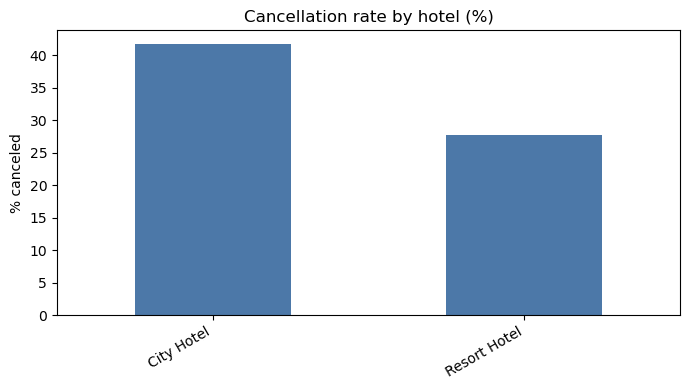

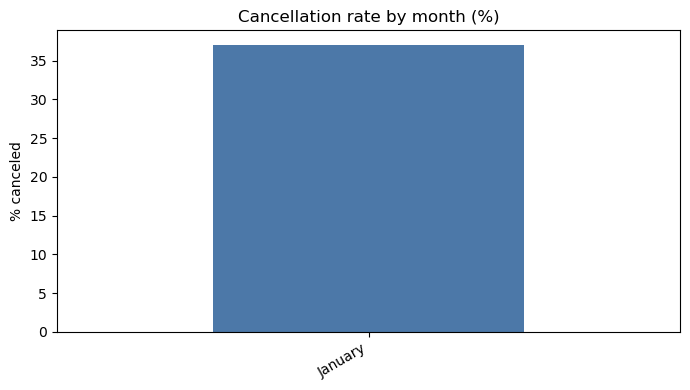

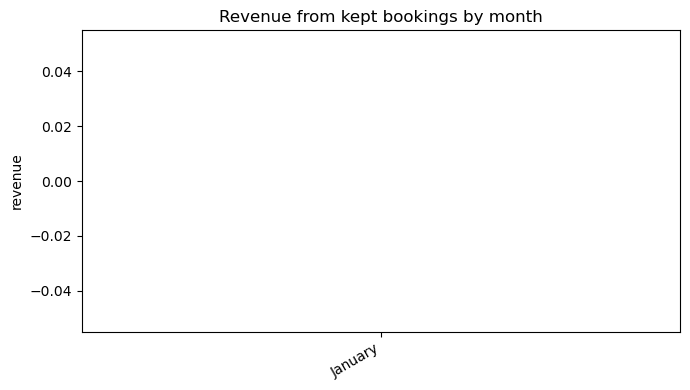

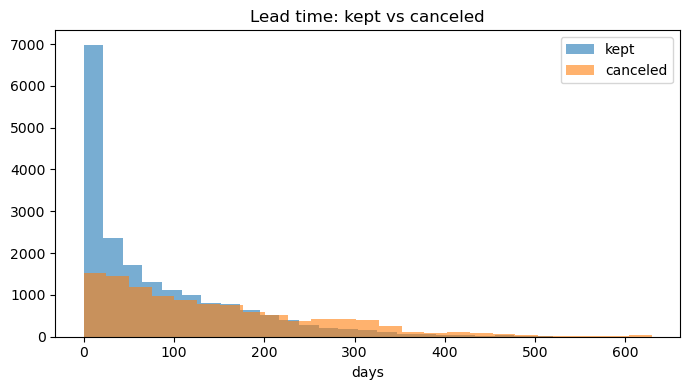

Saved charts: ['charts\\cancel_by_hotel.png', 'charts\\cancel_by_month.png', 'charts\\revenue_by_month.png', 'charts/lead_time.png']


In [17]:
import matplotlib
import matplotlib.pyplot as plt
os.makedirs("charts", exist_ok=True)
saved_charts = []

def bar_chart(series, title, ylabel, fname):
    if series is None or len(series) == 0:
        return
    fig, ax = plt.subplots(figsize=(7, 4))
    series.plot(kind="bar", ax=ax, color="#4C78A8")
    ax.set_title(title); ax.set_ylabel(ylabel); ax.set_xlabel("")
    plt.xticks(rotation=30, ha="right"); plt.tight_layout()
    path = os.path.join("charts", fname)
    fig.savefig(path, dpi=130); plt.show(); plt.close(fig)
    saved_charts.append(path)

for dim in ("hotel", "segment", "room"):
    c = COL.get(dim)
    if c in df.columns and df[c].nunique() <= 12:
        bar_chart(df.groupby(c)["is_canceled"].mean() * 100, f"Cancellation rate by {dim} (%)", "% canceled", f"cancel_by_{dim}.png")

if "month" in df.columns:
    order = ["January","February","March","April","May","June","July","August","September","October","November","December"]
    m = (df.groupby("month")["is_canceled"].mean() * 100).reindex([x for x in order if x in df["month"].unique()])
    bar_chart(m, "Cancellation rate by month (%)", "% canceled", "cancel_by_month.png")
    rv = df[df["is_canceled"] == 0].groupby("month")["revenue"].sum().reindex([x for x in order if x in df["month"].unique()])
    bar_chart(rv, "Revenue from kept bookings by month", "revenue", "revenue_by_month.png")

lt = COL.get("lead_time")
if lt in df.columns:
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.hist(df.loc[df["is_canceled"] == 0, lt], bins=25, alpha=0.6, label="kept")
    ax.hist(df.loc[df["is_canceled"] == 1, lt], bins=25, alpha=0.6, label="canceled")
    ax.set_title("Lead time: kept vs canceled"); ax.set_xlabel("days"); ax.legend(); plt.tight_layout()
    fig.savefig("charts/lead_time.png", dpi=130); plt.show(); plt.close(fig)
    saved_charts.append("charts/lead_time.png")
print("Saved charts:", saved_charts)

## 14. V1 demo run (new)
One cell that runs the whole flow in the order I explain it in the team demo: data -> cleaning -> validation -> statistics -> insights -> AI answer.

In [18]:
def run_demo(filters=None):
    print("=" * 70)
    print("V1 DEMO - Hotel booking analytics")
    print("=" * 70)
    print(f"1) Data: {df_raw.shape[0]} raw rows x {df_raw.shape[1]} columns -> {df.shape[0]} cleaned rows x {df.shape[1]} columns")
    print(f"2) Cleaning steps logged: {len(cleaning_log)} | validation FAIL on cleaned data: {n_fail_clean}")
    res = get_insights_for(filters, use_llm=True)
    if not res["ok"]:
        print("Request failed cleanly:", res["error"]); return res
    print(f"3) Selection: {filters or 'all bookings'} -> {res['rows']} bookings")
    print("4) Business insights:")
    for i in res["insights"]: print("   -", i)
    print("5) Recommendations:")
    for r in res["recommendations"]: print("   -", r)
    print("6) AI-written summary (grounded on the numbers above):")
    print(res["ai_text"][:1500])
    return res

demo_all = run_demo()
print()
demo_filtered = run_demo(example_filters)

V1 DEMO - Hotel booking analytics
1) Data: 30000 raw rows x 23 columns -> 30000 cleaned rows x 27 columns
2) Cleaning steps logged: 6 | validation FAIL on cleaned data: 0
3) Selection: all bookings -> 30000 bookings
4) Business insights:
   - 37.04% of the 30000 bookings were canceled.
   - Cancellations differ by hotel: City Hotel is highest at 41.73% and Resort Hotel is lowest at 27.76% (gap 13.97 points). This difference is statistically significant (p=0.0000).
   - Canceled bookings have a longer average lead time (142.38 days) than kept bookings (78.84 days).
5) Recommendations:
   - Consider a deposit or a reminder message for hotel = City Hotel bookings, where cancellations are highest.
   - Bookings made far in advance cancel more often, so send a confirmation reminder as the stay gets closer.
6) AI-written summary (grounded on the numbers above):
AI call skipped: set ANTHROPIC_API_KEY to enable it. The grounded prompt is built by build_prompt(stats).

V1 DEMO - Hotel booking a

## 15. Export for the team

In [19]:
final = get_insights_for(None)
with open("hotel_insights.json", "w") as f:
    json.dump(final, f, indent=2)
with open("cleaning_log.json", "w") as f:
    json.dump(cleaning_log, f, indent=2)
with open("column_mapping.json", "w") as f:
    json.dump(COL, f, indent=2)
validation_report.to_csv("validation_report.csv", index=False)
test_report.to_csv("test_report.csv", index=False)
df.to_csv("hotel_bookings_cleaned.csv", index=False)
print("Saved: hotel_insights.json, cleaning_log.json, column_mapping.json, validation_report.csv, test_report.csv, hotel_bookings_cleaned.csv, charts/")

Saved: hotel_insights.json, cleaning_log.json, column_mapping.json, validation_report.csv, test_report.csv, hotel_bookings_cleaned.csv, charts/


## 16. Auto-generated submission description (real numbers, no placeholders)
Fill in the three variables, run the cell, and paste the printed text into the submission form.

In [20]:
GITHUB_URL = ""      # your public repo link
TEAMMATES  = {}      # e.g. {"Alice": "backend/API", "Bob": "frontend/UI"}
MY_PART    = ""      # optional: one sentence on what you personally built

assert GITHUB_URL.startswith("http"), "Set GITHUB_URL to your public repo link first"
assert TEAMMATES, "Fill TEAMMATES with the real names and roles of your two teammates"

miss_raw = df_raw.isnull().sum()
miss_raw = miss_raw[miss_raw > 0]
miss_txt = ", ".join(f"{c}: {int(n)}" for c, n in miss_raw.items()) or "none"
steps_txt = "; ".join(f"{x['step']} ({x['detail']})" for x in cleaning_log)
team_txt = ", ".join(f"{n} ({r})" for n, r in TEAMMATES.items())
status_counts = validation_report[validation_report["dataset"] == "cleaned"]["status"].value_counts().to_dict()
lt_ = stats.get("lead_time", {})
lt_txt = ""
if lt_.get("not_canceled") and lt_.get("canceled"):
    lt_txt = (f" Lead time: kept mean {lt_['not_canceled']['mean']} / median {lt_['not_canceled']['median']} days, "
              f"canceled mean {lt_['canceled']['mean']} / median {lt_['canceled']['median']} days.")

description = f"""W3 Proof of Work - GenAI Agent Engineer (Phase 1 complete)

Data: hotel_bookings_with_1000_customers.csv. Raw shape {df_raw.shape[0]} rows x {df_raw.shape[1]} columns; cleaned shape {df.shape[0]} rows x {df.shape[1]} columns.
Missing values before cleaning: {miss_txt}.
Cleaning steps: {steps_txt}.
Validation (cleaned data): {status_counts}. The validation now reports PASS/WARN/FAIL for every check instead of stopping at the first assert.

Statistics: overall cancellation rate {stats['overall_cancellation']['rate_pct']}% over {stats['total_bookings']} bookings; average price {stats['avg_price']['avg_price']}; revenue from kept bookings {stats['total_revenue_kept_bookings']['total_revenue']}.{lt_txt}
Significance checks: {' '.join(sig_results)}

Business insights generated from the numbers:
{chr(10).join('- ' + i for i in insights[:6])}
Recommendations:
{chr(10).join('- ' + r for r in recommendations[:4])}

AI-feature logic: get_insights_for(filters) validates the filters, computes the statistics, builds the rule-based insights, and optionally sends only those numbers to the Anthropic Messages API (model claude-sonnet-5-5, max_tokens 500). The prompt forbids inventing numbers, and ungrounded_numbers() checks the answer against the input. Errors come back as {{'ok': False, 'error': ...}} instead of exceptions.

Testing: {n_pass}/{len(test_report)} tests passed, covering empty input, single row, all/none canceled, unknown column, unknown value, wrong filter type, injected nulls, injected negative price, missing file, and JSON serialization.

Team: my function returns JSON that {team_txt} use in the app. {MY_PART}

Code, notebook with outputs, charts and test report: {GITHUB_URL}"""

print(description)
open("submission_description_w3.md", "w").write(description)

AssertionError: Set GITHUB_URL to your public repo link first

## 17. How I explain it in the V1 demo (1 to 2 minutes)
**Python:** I load the CSV with error handling, clean it in logged steps (duplicates, dates, missing values, invalid rows, IQR outlier cap), and expose reusable functions that return JSON.

**Statistics:** I report cancellation rate with a 95% confidence interval, compare groups (hotel, segment, month), and test whether differences are real with chi-square and Mann-Whitney, so insights are not based on noise.

**AI feature:** The model never sees raw data. It only gets the calculated numbers and the rule-based insights, is told not to invent figures, and a check flags any number that was not in the input.

**Reliability:** Validation produces a PASS/WARN/FAIL report, the API function never crashes (it returns `ok` and `error`), and the test table shows what was tested.

**My part in the team:** I own the data processing, statistics and AI-insight logic. My teammates call `get_insights_for(filters)` from the app and show the output.